# Single-machine total weighted tardiness

Minimizing the total weighted tardiness of jobs with due dates (Pinedo, 2008, Section 3.6)

1 || $\sum_{j \in J}{w_j T_j}$

In [1]:
import gc
import random
import time

import pyomo.environ as pyo

from bnbprob.wtard import TransportOnly, WeightedTardiness
from bnbprob.wtard.milp import (
    disjunctive_model,
    positional_model,
    time_indexed_model,
)
from bnbpy import BranchAndBound, configure_logfile, plot_tree
from bnbpy.cython.levelqueue import CyclicBestSearch


In [2]:
# Disable garbage collection for better performance (if needed)
gc.disable()

In [3]:
configure_logfile('wtard.log', mode='w')

## Simple Problem

Example 3.6.3 in Pinedo (2008)

In [4]:
# Parameters
p = [12, 8, 15, 9]
w = [4, 5, 3, 5]
d = [16, 26, 25, 27]

# Instantiate problem
problem = TransportOnly.from_data(p, w, d)

# WSPT warmstart
ws = problem.warmstart()
print(f'Warmstart: {[job.index for job in ws.sequence]}')
print(f'Cost: {ws.calc_bound()}')

Warmstart: [0, 1, 3, 2]
Cost: 67


In [5]:
# Solve
bnb = BranchAndBound(problem, eval_node='in', save_tree=True)
sol = bnb.solve()
print(f'Nodes explored: {bnb.explored}')
print(sol)
print([job.index for job in sol.problem.sequence])

Nodes explored: 2
Status: OPTIMAL | Cost: 67.0 | LB: 67.0
[0, 1, 3, 2]


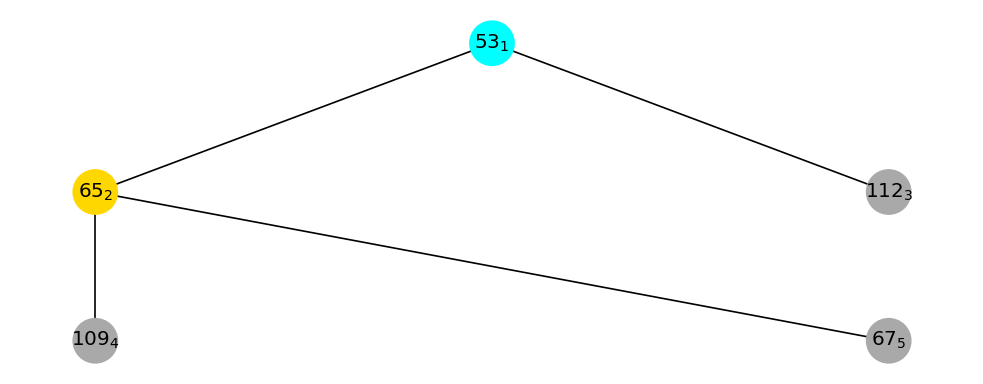

In [6]:
plot_tree(bnb.root, dpi=120, figsize=[8, 3])

## Randomized Larger Instance

Due dates are drawn from $U[P(1 - TF - RDD/2), P(1 - TF + RDD/2)]$, in which $P$ is the total processing time, $TF$ the tardiness factor and $RDD$ the relative range of due dates.

In [7]:
def random_instance(
    n: int,
    seed: int | None = None,
    pmax: int = 20,
    tf: float = 0.5,
    rdd: float = 0.6,
) -> tuple[list[int], list[int], list[int]]:
    rng = random.Random(seed)
    p = [rng.randint(1, pmax) for _ in range(n)]
    w = [rng.randint(1, 10) for _ in range(n)]
    total = sum(p)
    lo = max(int(total * (1 - tf - rdd / 2)), 0)
    hi = max(int(total * (1 - tf + rdd / 2)), lo)
    d = [rng.randint(lo, hi) for _ in range(n)]
    return p, w, d

In [8]:
# Parameters
n = 50
seed = 0
timelimit = 60

# Instantiate problem
p, w, d = random_instance(n, seed=seed)
problem = WeightedTardiness.from_data(p, w, d)

# Solve
bnb = BranchAndBound(problem, eval_node='in', save_tree=False)
bnb.set_manager(CyclicBestSearch(max_size=10_000))
sol = bnb.solve(timelimit=timelimit)
print(f'Nodes explored: {bnb.explored}')
print(sol)
print([job.index for job in sol.problem.sequence])

Nodes explored: 315
Status: OPTIMAL | Cost: 1405.0 | LB: 1405.0
[23, 41, 35, 31, 40, 13, 49, 32, 16, 25, 47, 42, 33, 28, 44, 21, 3, 26, 34, 2, 22, 24, 7, 0, 14, 29, 20, 12, 27, 48, 5, 30, 8, 9, 1, 38, 6, 18, 4, 39, 15, 11, 19, 10, 43, 36, 46, 17, 37, 45]


## MILP Models

Solve the same instance with the positional, disjunctive and time-indexed formulations.

### Positional

$$
 \begin{align}
     \text{min} \quad & \sum_{j \in J} w_j T_j \\
     \text{s.t.} \quad & \sum_{j \in J} x_{j,k} = 1
         & \forall ~ k \in K\\
     & \sum_{k \in K} x_{j,k} = 1
         & \forall ~ j \in J\\
     & C_{k-1} + \sum_{j \in J} p_j x_{j,k} \leq C_k
         & \forall ~ k \in K\\
     & C_k - d_j - M_{j,k} (1 - x_{j,k}) \leq T_j
         & \forall ~ j \in J; k \in K\\
     & C_k \geq 0 & \forall ~ k \in K\\
     & T_j \geq 0 & \forall ~ j \in J\\
     & x_{j,k} \in \{0, 1\} & \forall ~ j \in J; k \in K\\
 \end{align}
 $$

Where $x_{j,k}$ indicates that job $j$ is processed in position $k$, $C_k$ is the completion time of position $k$ (with $C_0 = 0$) and $T_j$ is the tardiness of job $j$. The big-M $M_{j,k} = \sum_{i = 1}^{k} p_{[i]} - d_j$, in which $p_{[i]}$ is the $i$-th largest processing time, uses the latest completion time of position $k$ without idle times. Tardiness constraints with $M_{j,k} \leq 0$ are omitted, as job $j$ is never late in position $k$.

### Disjunctive

$$
 \begin{align}
     \text{min} \quad & \sum_{j \in J} w_j T_j \\
     \text{s.t.} \quad & C_i + p_j \leq C_j + M (1 - z_{i,j})
         & \forall ~ i, j \in J; i \neq j\\
     & z_{i,j} + z_{j,i} = 1
         & \forall ~ i, j \in J; i \neq j\\
     & C_j - d_j \leq T_j
         & \forall ~ j \in J\\
     & p_j \leq C_j \leq T & \forall ~ j \in J\\
     & T_j \geq 0 & \forall ~ j \in J\\
     & z_{i,j} \in \{0, 1\} & \forall ~ i, j \in J; i \neq j\\
 \end{align}
 $$

Where $z_{i,j}$ indicates that job $i$ precedes job $j$, so that exactly one of $z_{i,j}$ and $z_{j,i}$ is active for each pair of jobs, and $C_j$ is the completion time of job $j$. The planning horizon $T = \sum_{j \in J} p_j$ is the total processing time, also used as the big-M $M = T$.

### Time-indexed

$$
 \begin{align}
     \text{min} \quad & \sum_{j \in J} \sum_{t = 0}^{T - p_j} c_{j,t} x_{j,t} \\
     \text{s.t.} \quad & \sum_{t = 0}^{T - p_j} x_{j,t} = 1
         & \forall ~ j \in J\\
     & \sum_{j \in J} \sum_{s = \max(0, t - p_j + 1)}^{\min(t, T - p_j)} x_{j,s} \leq 1
         & \forall ~ t \in \{0, \dots, T - 1\}\\
     & x_{j,t} \in \{0, 1\} & \forall ~ j \in J; t \in \{0, \dots, T - p_j\}\\
 \end{align}
 $$

Where $x_{j,t}$ indicates that job $j$ starts at time $t$, so that it completes within the planning horizon $T = \sum_{j \in J} p_j$ if $t \leq T - p_j$. Each capacity constraint allows at most one job in the unit time slot $[t, t + 1)$, occupied by job $j$ if it starts between $t - p_j + 1$ and $t$. The cost $c_{j,t} = w_j \max(t + p_j - d_j, 0)$ is the weighted tardiness of job $j$ when it starts at time $t$.

In [13]:
def solve_milp(
    model: pyo.ConcreteModel,
    solver: str = 'gurobi',
    timelimit: float = 60,
) -> None:
    start = time.perf_counter()
    opt = pyo.SolverFactory(solver, solver_io='python')
    opt.options['TimeLimit'] = timelimit
    res = opt.solve(model, load_solutions=False, tee=True)
    elapsed = time.perf_counter() - start
    print(
        f'{res.solver.termination_condition}'
        f' | Cost: {res.problem.upper_bound}'
        f' | LB: {res.problem.lower_bound}'
        f' | Time: {elapsed:.1f}s'
    )

In [14]:
for model_fn in [time_indexed_model]:#, positional_model, disjunctive_model]:
    print(model_fn.__name__)
    model = model_fn(p, w, d)
    solve_milp(model, timelimit=60)

time_indexed_model
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 12th Gen Intel(R) Core(TM) i5-1240P, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 16 logical processors, using up to 16 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 620 rows, 27980 columns and 345294 nonzeros (Min)
Model fingerprint: 0x876f8dd7
Model has 14122 linear objective coefficients
Variable types: 0 continuous, 27980 integer (27980 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 4e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Presolve time: 0.29s
Presolved: 620 rows, 27980 columns, 345294 nonzeros
Variable types: 0 continuous, 27980 integer (27980 binary)
Found heuristic solution: objective 19093.000000
Found heuristic solution: objective 19089.000000

Root relaxation: objective 

In [15]:
13*4 + 19*3

109